# Global drought masks

### Functions

In [1]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cmocean
import matplotlib
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from matplotlib.lines import Line2D
import cartopy
import cartopy.crs as ccrs
import numpy as np
import os 
import glob
import sys
import datetime as dt
import datetime
import pandas as pd
import geopandas as gpd
import calendar
import netCDF4 as nc4
import xarray as xr
from dateutil import relativedelta
from datetime import timedelta
from calendar import monthrange
import regionmask
import string
from xhistogram.xarray import histogram
#xr.set_options(display_expand_attrs=False)

sys.path.insert(0, '..')
sys.path.insert(0, '../..')

### Plot settings

In [2]:
# version 1
plot_type  = 'pcolormesh'
mylevels = [-10,-2,-1.5,-1,1,1.5,2,10]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames = ["extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

### C3S mask

<xarray.Dataset> Size: 4MB
Dimensions:  (time: 1, lon: 1440, lat: 721)
Coordinates:
  * time     (time) datetime64[ns] 8B 2024-01-01
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    mask     (time, lat, lon) float32 4MB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Tue Oct 22 11:53:38 2024: cdo -f nc copy -chname,var141,mas...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


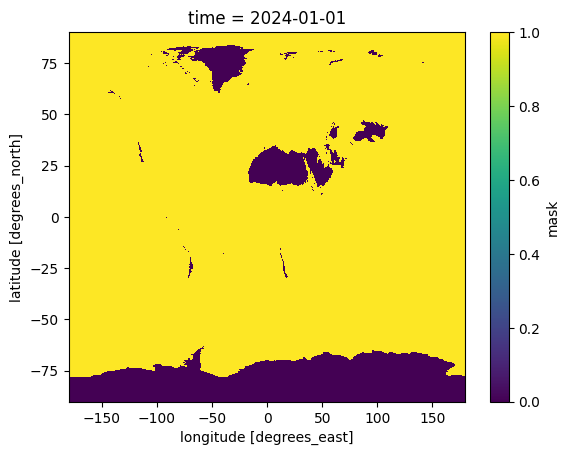

In [3]:
c3s_file = f"/ec/vol/centaur/nejk/veg_data/era5_mask/other_masks/c3s_mask/swvl1_ea_mask_202401.nc"
c3s_mask = xr.open_dataset(c3s_file)
print(c3s_mask)
# shift longitudes from 0/360 to -180/+180
if c3s_mask.coords['lon'].max() > 300:
    c3s_mask.coords['lon'] = (c3s_mask.coords['lon'] + 180) % 360 - 180
    c3s_mask = c3s_mask.sortby(c3s_mask.lon)
c3s_mask['mask'].plot()

### C3S mask with landmask

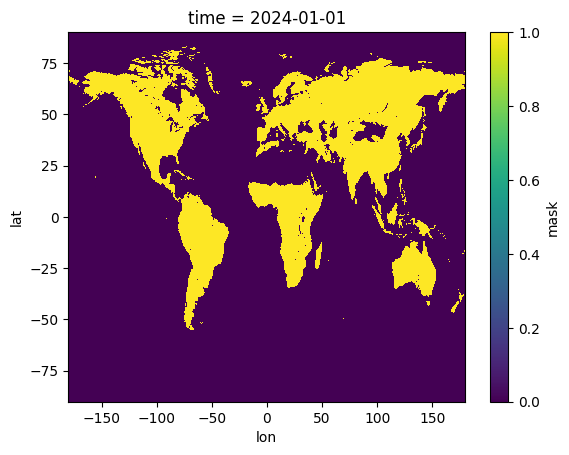

In [4]:
vfile = f"/ec/vol/centaur/nejk/veg_data/era5_mask/era5_static_025x025.nc"
vdata = xr.open_dataset(vfile)
# shift longitudes from 0/360 to -180/+180
if vdata.coords['lon'].max() > 300:
    vdata.coords['lon'] = (vdata.coords['lon'] + 180) % 360 - 180
    vdata = vdata.sortby(vdata.lon)
    
#c3s_mask['mask'] = xr.where(vdata['var172'].isel(time=0) == 0, 0, c3s_mask['mask'])
c3s_mask['mask'] = xr.where(vdata['var172'].isel(time=0) < 0.5, 0, c3s_mask['mask'])
c3s_mask['mask'].plot()

### Climate Atlas mask

<xarray.Dataset> Size: 8MB
Dimensions:  (lon: 1440, lat: 721)
Coordinates:
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    mask     (lat, lon) float64 8MB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Tue Oct 22 11:55:44 2024: cdo -chname,barrean,mask -invertl...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


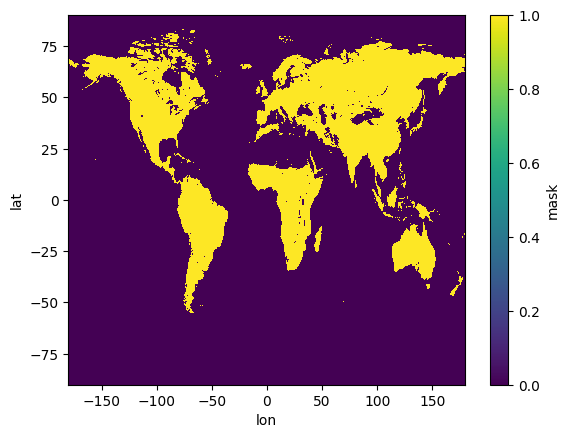

In [5]:
ca_file = f"/ec/vol/centaur/nejk/veg_data/era5_mask/other_masks/climate_atlas/barrean_mask_ERA5_mod.nc"
ca_mask = xr.open_dataset(ca_file)
print(ca_mask)
# shift longitudes from 0/360 to -180/+180
if ca_mask.coords['lon'].max() > 300:
    ca_mask.coords['lon'] = (ca_mask.coords['lon'] + 180) % 360 - 180
    ca_mask = ca_mask.sortby(ca_mask.lon)
ca_mask['mask'].plot()

### New ERA5 mask

In [6]:
vfile = f"/ec/vol/centaur/nejk/veg_data/era5_mask/era5_static_025x025.nc"
vdata = xr.open_dataset(vfile)
print(vdata)
# shift longitudes from 0/360 to -180/+180
if vdata.coords['lon'].max() > 300:
    vdata.coords['lon'] = (vdata.coords['lon'] + 180) % 360 - 180
    vdata = vdata.sortby(vdata.lon)

<xarray.Dataset> Size: 199MB
Dimensions:  (time: 12, lon: 1440, lat: 721)
Coordinates:
  * time     (time) datetime64[ns] 96B 2023-01-01T12:00:00 ... 2023-12-01T12:...
  * lon      (lon) float64 12kB 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    var27    (time, lat, lon) float32 50MB ...
    var28    (time, lat, lon) float32 50MB ...
    var141   (time, lat, lon) float32 50MB ...
    var172   (time, lat, lon) float32 50MB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Tue Oct 22 09:40:16 2024: cdo -f nc copy era5_static era5_s...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


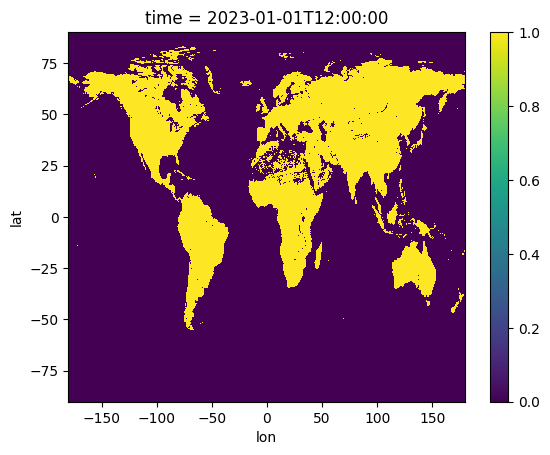

In [7]:
min_landfrac = 0
# var27 - low vegetation cover
# var28 - high vegetation cover
# var141 - snow depth (10m = glacier)
# var172 - land-sea mask
mask = xr.where(vdata['var172'].isel(time=0) > min_landfrac, 1, 0)
mask = xr.where(vdata['var141'].isel(time=0) >= 10, 0, mask)
mask = xr.where( ((vdata['var27'].isel(time=0) == 0) & (vdata['var28'].isel(time=0) == 0)), 0, mask)
mask.plot()

In [8]:
print(mask)
fmask = mask.to_dataset(name='barren_mask')
fmask.to_netcdf("/ec/vol/centaur/nejk/veg_data/era5_mask/ERA5_barren_wo_precip.nc")

<xarray.DataArray (lat: 721, lon: 1440)> Size: 8MB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    time     datetime64[ns] 8B 2023-01-01T12:00:00
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8


### New ERA5 mask with precipitation criterion

#### using quick-and-dirty Pmean

<xarray.Dataset> Size: 4MB
Dimensions:    (time: 1, bnds: 2, lon: 1440, lat: 721)
Coordinates:
  * time       (time) datetime64[ns] 8B 2005-12-16T06:00:00
  * lon        (lon) float64 12kB 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8
  * lat        (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 16B ...
    var228     (time, lat, lon) float32 4MB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Tue Oct 22 15:02:47 2024: cdo -f nc copy -mulc,1000 -timmea...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


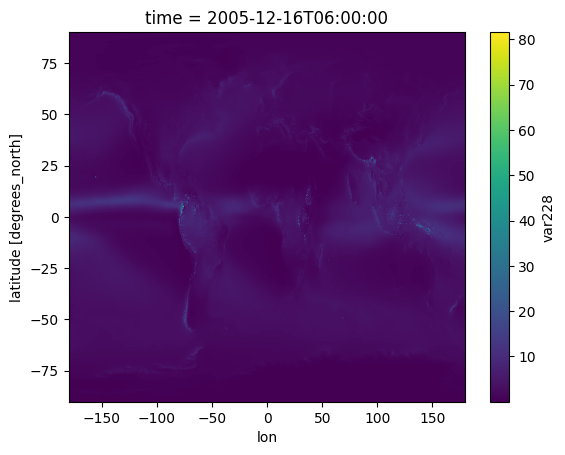

In [9]:
# quick timmean on moda stream using cdo
pfile = f"/ec/vol/centaur/nejk/veg_data/era5_mask/era5_precip_025x025_ref_mean.nc"
pdata = xr.open_dataset(pfile)
print(pdata)
# shift longitudes from 0/360 to -180/+180
if pdata.coords['lon'].max() > 300:
    pdata.coords['lon'] = (pdata.coords['lon'] + 180) % 360 - 180
    pdata = pdata.sortby(pdata.lon)
pdata['var228'].plot()

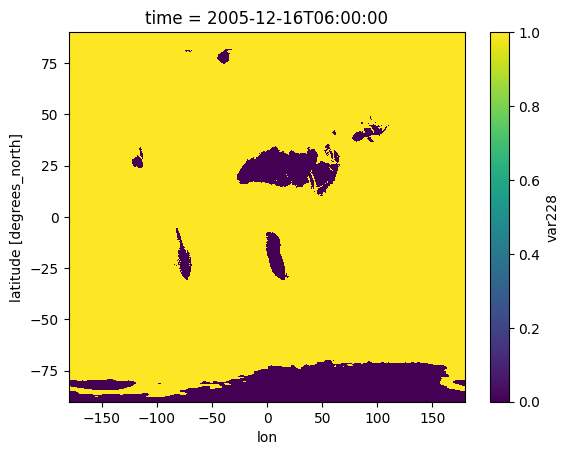

In [10]:
pmask_1 = xr.where(pdata['var228'] < 0.3, 0, 1)
pmask_1.plot()

#### using exact Pmean

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 360, lon: 1440, lat: 721)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1990-12-31T18:00:00 ... 2020-11-30T18:...
  * lon      (lon) float64 12kB 0.0 0.25 0.5 0.75 ... 359.0 359.2 359.5 359.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0
Data variables:
    var228   (time, lat, lon) float32 1GB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Tue Oct 22 14:59:27 2024: cdo -f nc copy -mulc,1000 era5_pr...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


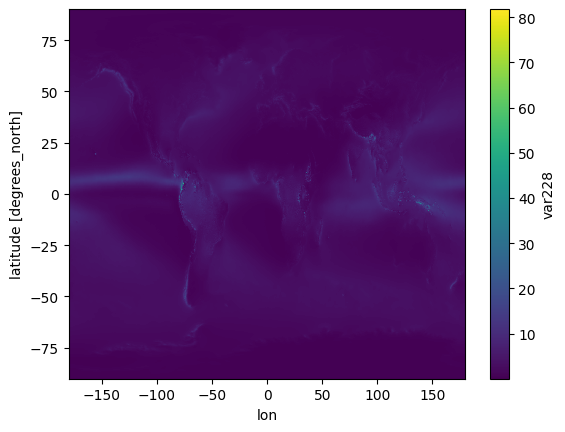

In [11]:
# exact daily precip, using all months during reference period from moda stream
# here multiplying with days in month and averaging 
p2file = f"/ec/vol/centaur/nejk/veg_data/era5_mask/era5_precip_025x025_ref.nc"
p2data = xr.open_dataset(p2file)
print(p2data)
# shift longitudes from 0/360 to -180/+180
if p2data.coords['lon'].max() > 300:
    p2data.coords['lon'] = (p2data.coords['lon'] + 180) % 360 - 180
    p2data = p2data.sortby(p2data.lon)
#p2data['var228'].isel(time=0).plot()

# number of days in month
ndays = []
for itime in range(p2data['var228'].shape[0]):
    # date in file, convert from np.datetime64 to datetime.datetime
    fdate = dt.datetime.utcfromtimestamp(int(p2data.isel(time=itime).time.values)/1e9)
    # add 6h or 1day, because this is based on forecast and thus shifted by -6h
    idate = fdate + dt.timedelta(days=1)
    # get number of days in month
    ndays.append(monthrange(idate.year, idate.month)[1])
ndays_xr = xr.DataArray(ndays, dims=['time'], coords=[p2data.time])

# multiply with days in month to get total precipitation
p2data_mod = p2data * ndays_xr
# and now calculate sum over the reference period and divide by number of days
p2data_modmean = p2data_mod.sum(dim='time') / ndays_xr.sum()
p2data_modmean['var228'].plot()
#test1 = (p2data['var228'].isel(time=1) * 28)
#test2 = (p2data_mod['var228'].isel(time=1))
#(test2 - test1).plot()

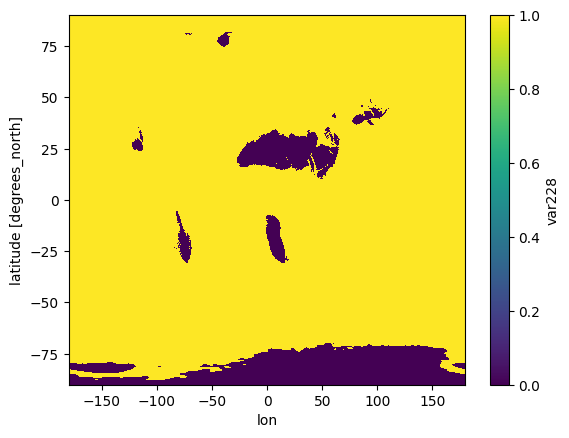

In [12]:
pmask_2 = xr.where(p2data_modmean['var228'] < 0.3, 0, 1)
pmask_2.plot()

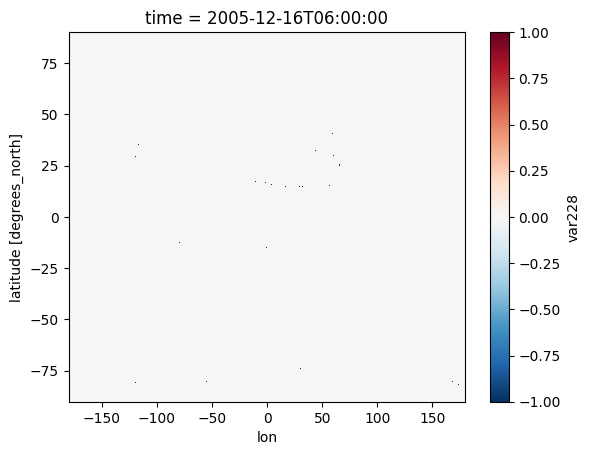

In [13]:
(pmask_2 - pmask_1).plot()

#### Now mask

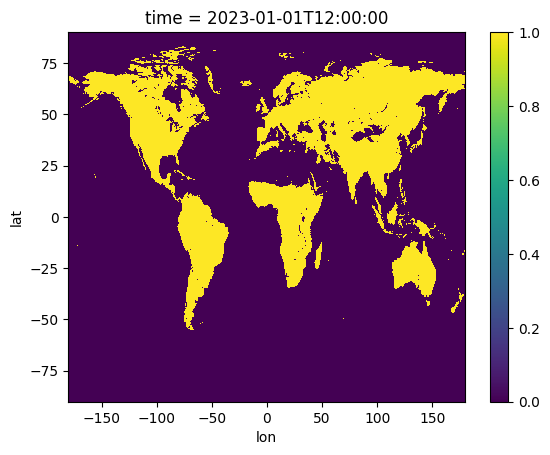

In [14]:
#mask = xr.where(pmask_1 == 0, 0, mask)
mask = xr.where(pmask_2 == 0, 0, mask)
mask.plot()

In [15]:
fmask = mask.to_dataset(name='barren_mask')
fmask.to_netcdf("/ec/vol/centaur/nejk/veg_data/era5_mask/ERA5_barren_w_precip.nc")

## Differences between masks

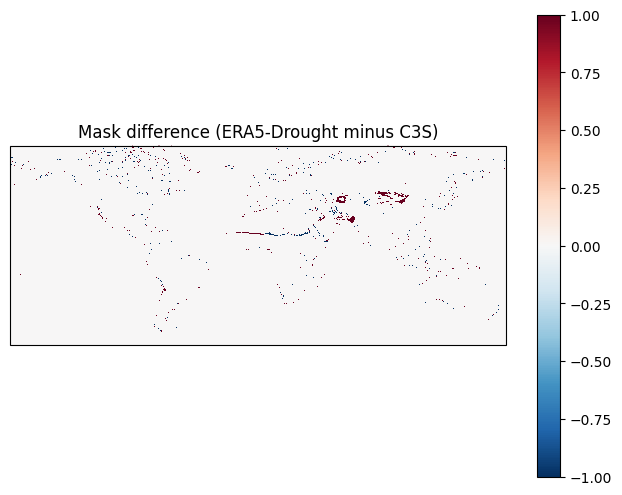

In [16]:
fig, ax = plt.subplots(1,1, figsize=(8,6), subplot_kw={'projection': ccrs.PlateCarree()})
(mask - c3s_mask['mask']).plot(ax=ax)
ax.set_ylim(-65,80)
ax.set_title("Mask difference (ERA5-Drought minus C3S)")
plt.savefig("figures/Mask_differences_ERA5_C3S.pdf",format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1, dpi=300,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

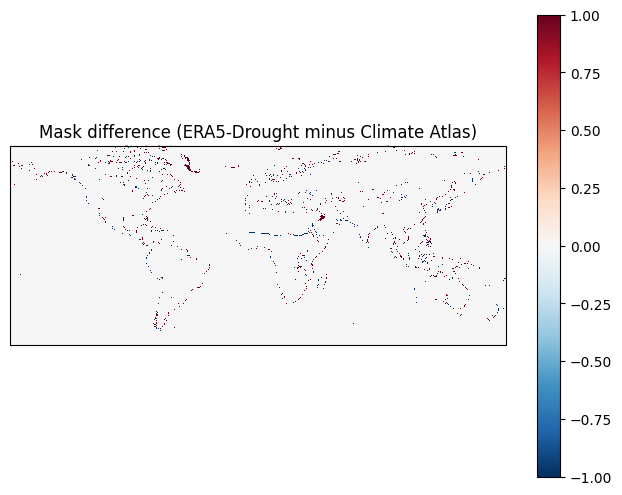

In [17]:
fig, ax = plt.subplots(1,1, figsize=(8,6), subplot_kw={'projection': ccrs.PlateCarree()})
(mask - ca_mask['mask']).plot(ax=ax)
ax.set_ylim(-65,80)
ax.set_title("Mask difference (ERA5-Drought minus Climate Atlas)")
plt.savefig("figures/Mask_differences_ERA5_CA.pdf",format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1, dpi=300,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

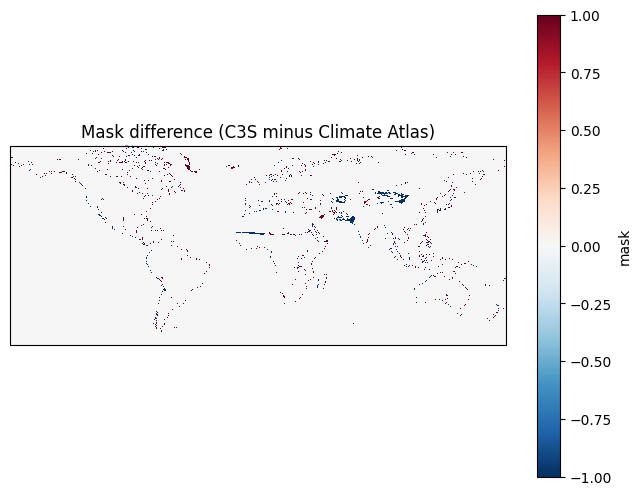

In [18]:
fig, ax = plt.subplots(1,1, figsize=(8,6), subplot_kw={'projection': ccrs.PlateCarree()})
(c3s_mask['mask'] - ca_mask['mask']).plot(ax=ax)
ax.set_ylim(-65,80)
ax.set_title("Mask difference (C3S minus Climate Atlas)")
plt.savefig("figures/Mask_differences_C3S_CA.pdf",format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1, dpi=300,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()